## Exploring temperature anomalies with the ESMValCore API. 

##### For general information on what is ESMValCore API and how to use it in Jupyter Notebook, see official ESMValTool tutorial here https://tutorial.esmvaltool.org/11-esmvalcoreapi/index.html. 

This notebook complements the recipe and diagnostic that were demonstrated during the seminar. It configures ESMValCore for Binder to download missing data.\
Keep in mind that the analysis can require substantial data access and memory.

# 1. Configure ESMValCore for Binder

In [ ]:
import os
from pathlib import Path

# Find esmvaltool_config whether Jupyter starts in the repository root
# or in the ESMValTool subfolder.
config_dir = None
for base in (Path.cwd(), *Path.cwd().parents):
    candidates = (base / "ESMValTool" / "esmvaltool_config",
                  base / "esmvaltool_config")
    config_dir = next(
        (path for path in candidates if (path / "data-intake-esgf.yml").is_file()),
        None,
    )
    if config_dir is not None:
        break

if config_dir is None:
    raise FileNotFoundError(
        "Could not find esmvaltool_config/data-intake-esgf.yml. "
        "Keep the config folder beside this notebook's ESMValTool folder."
    )

os.environ["ESMVALTOOL_CONFIG_DIR"] = str(config_dir.resolve())

print("ESMValCore config directory:", config_dir)


In [ ]:
# CFG is a configuration dictionary given by configuration file 

from esmvalcore.config import CFG
print("Configured CMIP6 data source:", CFG.get("projects", {}).get("CMIP6", {}).get("data", {}))

# CFG

In [ ]:
# Lets use temporary Binder storage for downloaded ESGF files.

from pathlib import Path
import intake_esgf

DATA_DIR = Path("/tmp/esmvaltool_cmip6")
DATA_DIR.mkdir(parents=True, exist_ok=True)
intake_esgf.conf.set(local_cache=[str(DATA_DIR)], num_threads=2)

print("ESGF download cache:", intake_esgf.conf["local_cache"])

# 2. Define the dataset

In [2]:
from esmvalcore.dataset import Dataset

dataset = Dataset(
    short_name="tas",
    mip="Amon",
    project="CMIP6",
    dataset="ACCESS-CM2",
    exp=["historical", "ssp585"],
    ensemble="r1i1p1f1",
    grid="gn",
    timerange="1850/2024",
)
dataset.augment_facets()
print(dataset)

Dataset:
{'dataset': 'ACCESS-CM2',
 'project': 'CMIP6',
 'mip': 'Amon',
 'short_name': 'tas',
 'activity': ['CMIP', 'ScenarioMIP'],
 'ensemble': 'r1i1p1f1',
 'exp': ['historical', 'ssp585'],
 'frequency': 'mon',
 'grid': 'gn',
 'institute': ['CSIRO-ARCCSS'],
 'long_name': 'Near-Surface Air Temperature',
 'modeling_realm': ['atmos'],
 'original_short_name': 'tas',
 'standard_name': 'air_temperature',
 'timerange': '1850/2024',
 'units': 'K'}
session: 'session-6da927bd-517e-48ed-aa53-fd60e1f94f19_20261116_145946'


# 3. Find data on ESGF. 
Lets check if the requested files can be found.


In [ ]:
files = dataset.files
print(f"Found {len(files)} matching ESGF data item(s)")
for file in files:
    print(file)

if not files:
    raise RuntimeError(
        "No matching data were found. Check the ACCESS-CM2 facets and ESGF availability."
    )

Found 2 file(s)
/home/galytska/online_seminar/input_data/CMIP6/CMIP/CSIRO-ARCCSS/ACCESS-CM2/historical/r1i1p1f1/Amon/tas/gn/v20191108/tas_Amon_ACCESS-CM2_historical_r1i1p1f1_gn_185001-201412.nc
/home/galytska/online_seminar/input_data/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCESS-CM2/ssp585/r1i1p1f1/Amon/tas/gn/v20210317/tas_Amon_ACCESS-CM2_ssp585_r1i1p1f1_gn_201501-210012.nc


# 4.Load the source cube and inspect it



In [4]:
cube = dataset.load()
# cube

# 5. Match the recipe's preprocessing steps

The **recipe_temperature_anomalies.yml** has introduced the step-by-step preprocessing of data. Lets now reproduce those steps here. 

In [5]:
from esmvalcore.preprocessor import (
    anomalies,
    annual_statistics,
    climate_statistics,
    convert_units,
    extract_region,
    extract_time,
    area_statistics
)

reference = {
    "start_year": 1981, "start_month": 1, "start_day": 1,
    "end_year": 2010, "end_month": 12, "end_day": 31,
}
analysis_period = {
    "start_year": 1979, "start_month": 1, "start_day": 1,
    "end_year": 2024, "end_month": 12, "end_day": 31,
}

def load_tas():
    return dataset.load()

def add_monthly_anomalies(cube):
    cube = convert_units(cube, units="degrees_C")
    cube = anomalies(cube, period="month", reference=reference)
    return extract_time(cube, **analysis_period)

# 6. Lets calculate and plot temperature anomalies

### Global monthly temperature anomalies for 1979-2024 referenced to 1981-2010

In [6]:
tas_map_cube = add_monthly_anomalies(load_tas())
tas_map_cube = climate_statistics(tas_map_cube, operator="mean", period="full")
# tas_map_cube

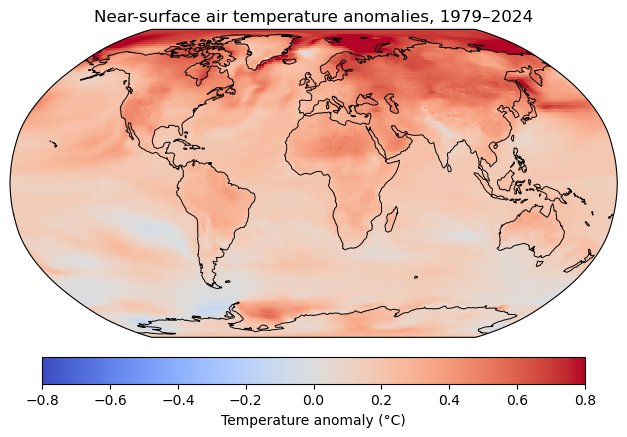

In [7]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

data = np.squeeze(np.asarray(tas_map_cube.data, dtype=float))
lon = tas_map_cube.coord("longitude").points
lat = tas_map_cube.coord("latitude").points
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={"projection": ccrs.Robinson()})
mesh = ax.pcolormesh(lon, lat, data, vmin=-0.8, vmax=0.8, transform=ccrs.PlateCarree(), cmap="coolwarm", shading="auto")
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title("Near-surface air temperature anomalies, 1979–2024")
fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.7, pad=0.05, label="Temperature anomaly (°C)")
plt.show()

### Monthly Arctic anomalies: 65–90°N, zonal mean then meridional mean


In [8]:
tas_arctic_cube = add_monthly_anomalies(load_tas())
tas_arctic_cube = extract_region(
    tas_arctic_cube, start_longitude=0, end_longitude=360,
    start_latitude=65, end_latitude=90,
)
tas_arctic_cube = area_statistics(tas_arctic_cube, operator="mean")
# tas_arctic_cube

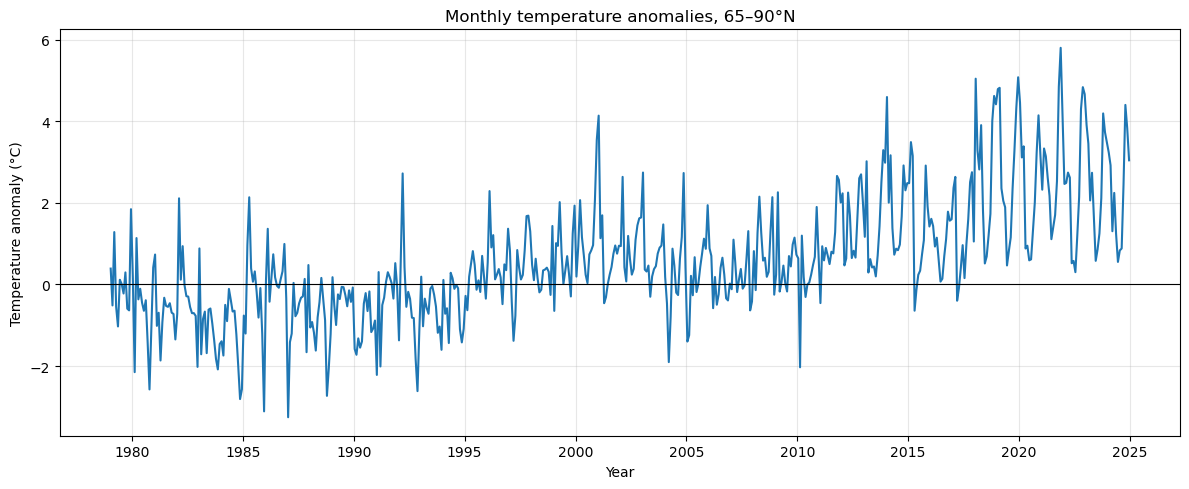

In [9]:
time = tas_arctic_cube.coord("time")
dates = time.units.num2date(time.points, only_use_cftime_datetimes=False, only_use_python_datetimes=True)
temperature = np.squeeze(np.asarray(tas_arctic_cube.data, dtype=float))
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dates, temperature, linewidth=1.5)
ax.axhline(0, linewidth=0.8, color="black")
ax.set_xlabel("Year")
ax.set_ylabel("Temperature anomaly (°C)")
ax.set_title("Monthly temperature anomalies, 65–90°N")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### Annual Arctic anomalies for the warming stripes


In [10]:
tas_arctic_annual_cube = add_monthly_anomalies(load_tas())
tas_arctic_annual_cube = extract_region(
    tas_arctic_annual_cube, start_longitude=0, end_longitude=360,
    start_latitude=65, end_latitude=90,
)

tas_arctic_annual_cube = area_statistics(tas_arctic_annual_cube, operator="mean")
tas_arctic_annual_cube = annual_statistics(tas_arctic_annual_cube, operator="mean")
# tas_arctic_annual_cube

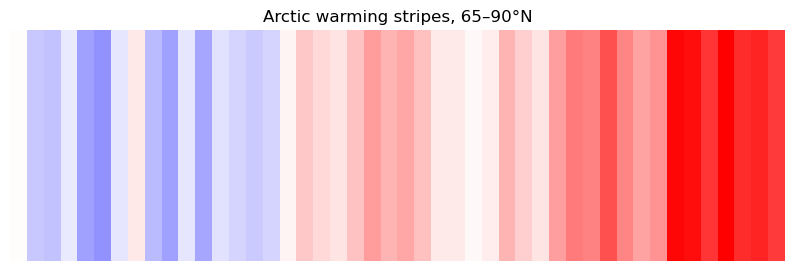

In [11]:
import matplotlib as mpl
annual = np.squeeze(np.asarray(tas_arctic_annual_cube.data, dtype=float))
limit = np.nanmax(np.abs(annual))
fig, ax = plt.subplots(figsize=(10, 3))
ax.pcolormesh(np.arange(len(annual)), [0, 1], np.vstack([annual, annual]), cmap="bwr", norm=mpl.colors.Normalize(-limit, limit), shading="auto")
ax.set_axis_off()
ax.set_title("Arctic warming stripes, 65–90°N")
plt.show()